### Comparison between SteadierCom and experimental results

In [213]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy as sp

import json
import csv
import warnings
from os import listdir
import reframed

import libsbml
import matplotlib.pyplot as plt

import sys
sys.path.append("../functions/")
import compare_inter_exp_sim.venturelli2018 as venturelli2018

import compare_inter_exp_sim.correlation as correlation


In [214]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [226]:
signal_exp = venturelli2018.load_experimental_results()

In [227]:
simulation_dict = venturelli2018.load_simulation_results()


In [228]:
simulated_test = pd.DataFrame(
    {"donor": ["environment","C","C","environment"],
 "receiver":["C","A","B","B"],
 "compound":["c2","c3","c3","c3"],
"metric":[1.0,1,1.0,1.0]})
simulated_test

,donor,receiver,compound,metric
0,environment,C,c2,1.0
1,C,A,c3,1.0
2,C,B,c3,1.0
3,environment,B,c3,1.0


In [229]:
exp_signal_test = pd.Series({("A","B"):1,
                            ("A","C"):1,
                             ("B","A"):1,
                             ("B","C"):1,
                             ("C","A"):1,
                             ("C","B"):1})
exp_signal_test.index.names = ["member_second","member_main"]
exp_signal_test.name = "experimental"
exp_signal_test

member_second  member_main
A              B              1
               C              1
B              A              1
               C              1
C              A              1
               B              1
Name: experimental, dtype: int64

In [237]:
correlation._merge_exp_sim(simulated_test,exp_signal_test,coop_or_comp="coop",metric="metric")

experimental  simulated
member_second member_main                         
A             B                       1        NaN
              C                       1        NaN
B             A                       1        NaN
              C                       1        NaN
C             A                       1        1.0
              B                       1        0.5

In [238]:
correlation._merge_exp_sim(simulated_test,exp_signal_test,coop_or_comp="comp",metric="metric")

experimental  simulated
member_second member_main                         
A             B                       1        1.0
              C                       1        0.0
B             A                       1        1.0
              C                       1        0.0
C             A                       1        0.0
              B                       1        0.0

## Cooperation and competition - SteadierCom

#### SteadierCom - scatterplot - frequency count

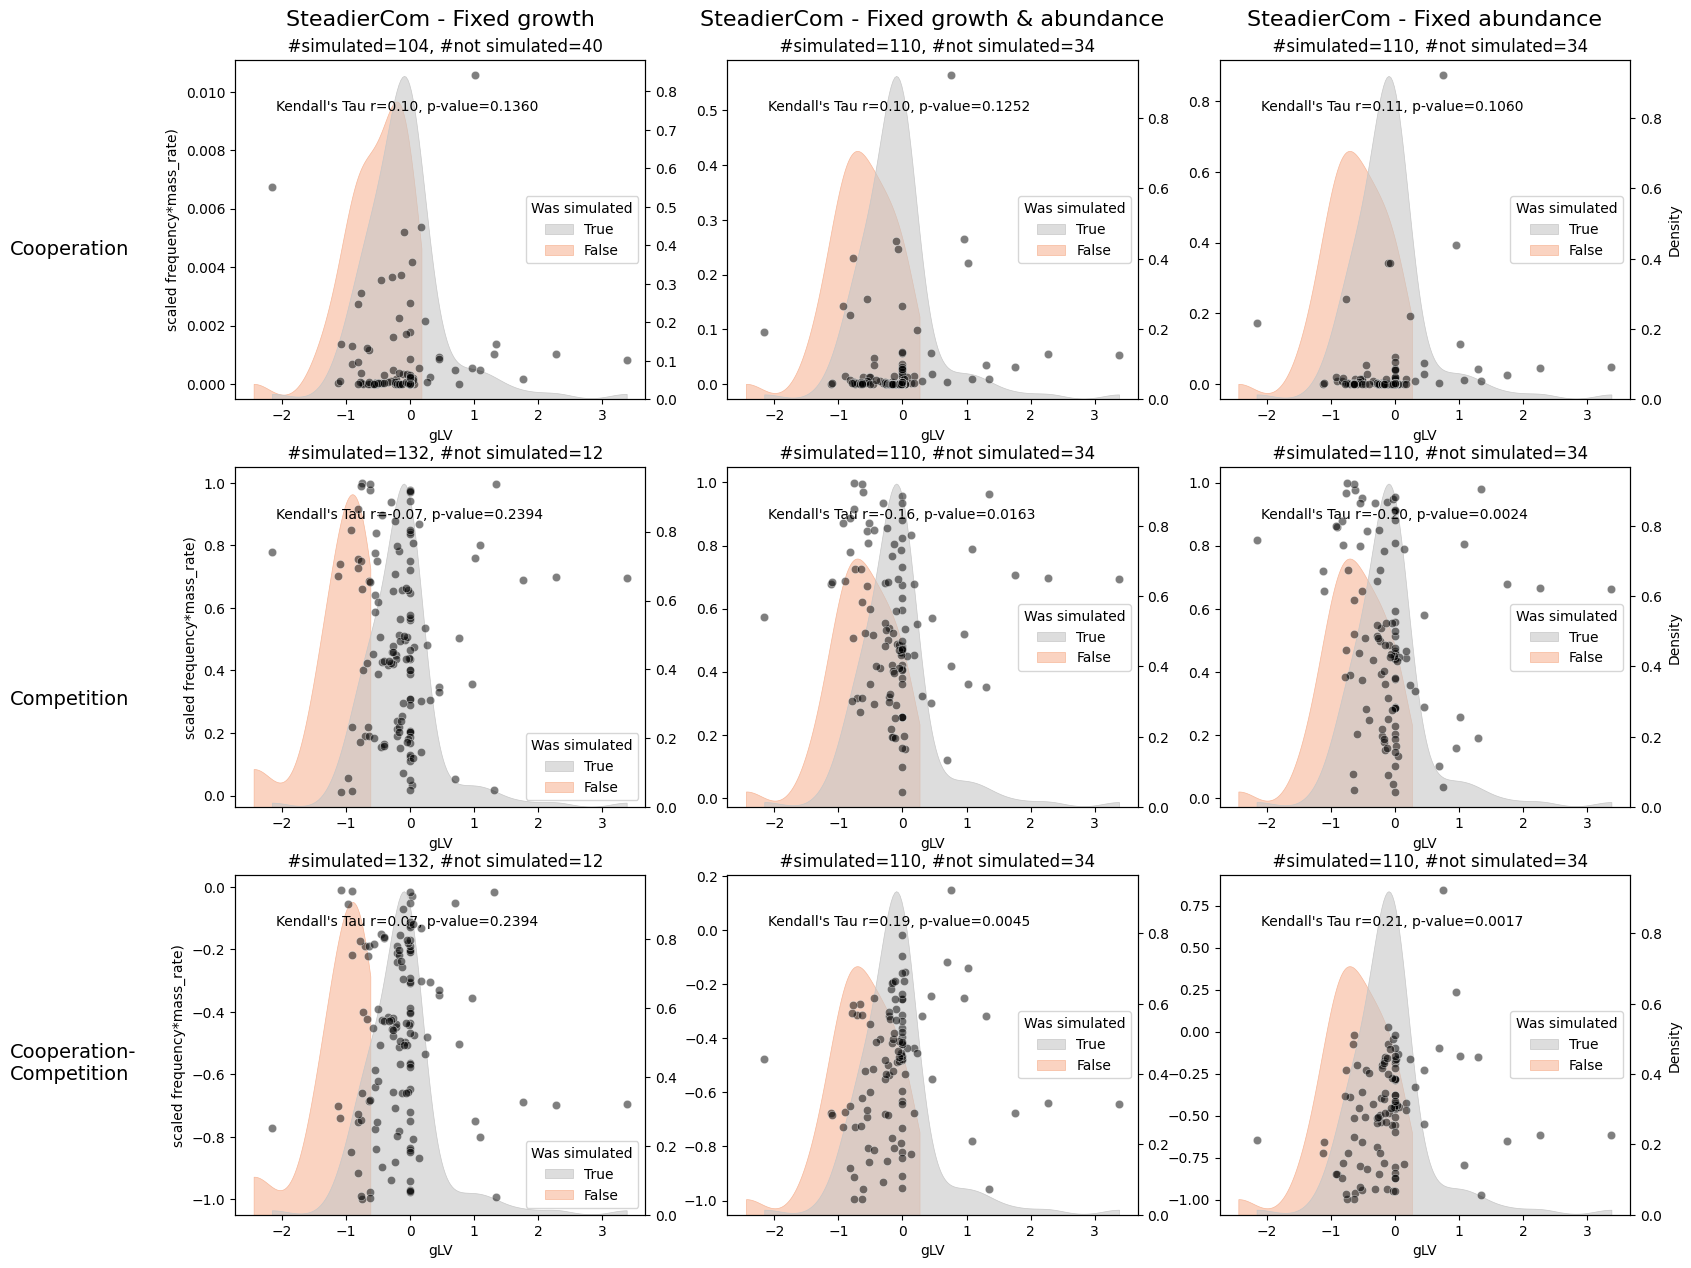

In [243]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency*mass_rate")

In [253]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)


In [254]:
counts

,second_count,main_count
member_second,,
BH,2.111111,2.111111
BO,1.777778,1.777778
BT,2.111111,2.111111
BU,4.666667,4.666667
BV,1.888889,1.888889
CA,1.888889,1.888889
CH,1.888889,1.888889
DP,1.666667,1.666667
EL,1.666667,1.666667


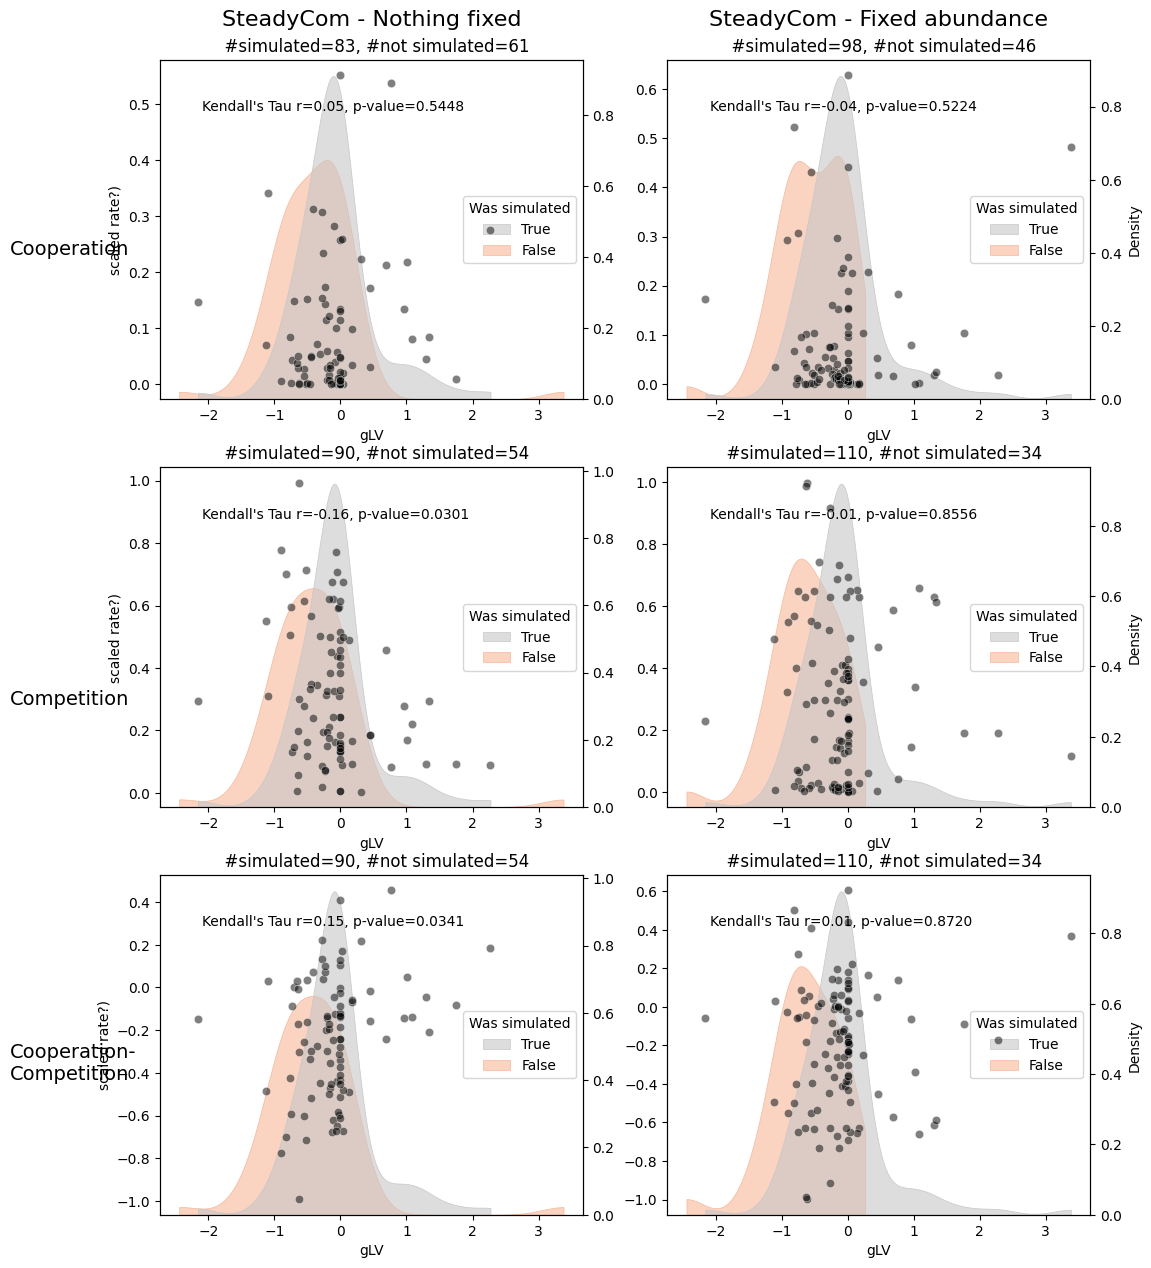

In [251]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,signal_exp,simulation_method="steadycom",metric="rate?")